# Exploratory Data Analysis & Extended Statistical Computations
**Role:** Junior Data Analyst
**Objective:** Perform numerical analysis, generate visualizations, and interpret trends, relationships, and anomalies within the contaminated customer datasets.

In [5]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the datasets
# (Note: Ensure the exact filenames match your directory)
demo_df = pd.read_csv("customer_demographics_contaminated (1).csv")
social_df = pd.read_csv("social_media_interactions_contaminated.csv")
trans_df = pd.read_csv("customer_transactions_contaminated.csv")

## Step 2: Data Cleaning & Numerical Computations
Before computing advanced statistics, we must clean the textual anomalies (e.g., "Free", "Unknown") from intended numerical columns. We will then use NumPy to extract the Mean, Median, Variance, Standard Deviation, and Min/Max values.

In [6]:
# Coerce numeric columns to handle text artifacts (converts text to NaN)
demo_df['Age_Num'] = pd.to_numeric(demo_df['Age'], errors='coerce')
trans_df['Amount_Num'] = pd.to_numeric(trans_df['Amount'], errors='coerce')

# Filter out impossible biological ages (e.g., < 18 or > 100) and negative amounts
demo_df_clean = demo_df[(demo_df['Age_Num'] >= 18) & (demo_df['Age_Num'] <= 100)].copy()
trans_df_clean = trans_df[trans_df['Amount_Num'] > 0].copy()

# Perform NumPy statistical computations
age_stats = {
    'Mean': np.mean(demo_df_clean['Age_Num']),
    'Median': np.median(demo_df_clean['Age_Num']),
    'Std Dev': np.std(demo_df_clean['Age_Num']),
    'Variance': np.var(demo_df_clean['Age_Num']),
    'Min': np.min(demo_df_clean['Age_Num']),
    'Max': np.max(demo_df_clean['Age_Num'])
}

amount_stats = {
    'Mean': np.mean(trans_df_clean['Amount_Num']),
    'Median': np.median(trans_df_clean['Amount_Num']),
    'Std Dev': np.std(trans_df_clean['Amount_Num']),
    'Variance': np.var(trans_df_clean['Amount_Num']),
    'Min': np.min(trans_df_clean['Amount_Num']),
    'Max': np.max(trans_df_clean['Amount_Num'])
}

# Display results
print("--- Cleaned Age Statistics ---")
for k, v in age_stats.items():
    print(f"{k}: {v:.2f}")

print("\n--- Cleaned Transaction Amount Statistics ---")
for k, v in amount_stats.items():
    print(f"{k}: {v:.2f}")

--- Cleaned Age Statistics ---
Mean: 44.59
Median: 45.00
Std Dev: 15.39
Variance: 236.75
Min: 18.00
Max: 70.00

--- Cleaned Transaction Amount Statistics ---
Mean: 504.64
Median: 508.07
Std Dev: 289.27
Variance: 83676.88
Min: 10.03
Max: 999.86


## Steps 3, 4, 5, & 6: Generating Visualizations
The exploratory analysis revealed that `Age` and `Amount` require distribution tracking, `ProductCategory` and `Sentiment` require categorical frequency tracking, and checking for relationships between `Age` and `Amount` could yield business insights.

C:\Users\ramos\AppData\Local\Temp\ipykernel_29380\3216440281.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=trans_df, y='ProductCategory', order=trans_df['ProductCategory'].value_counts().index, ax=axes[1, 0], palette='viridis')
C:\Users\ramos\AppData\Local\Temp\ipykernel_29380\3216440281.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=social_df, x='Sentiment', order=social_df['Sentiment'].value_counts().index, ax=axes[1, 1], palette='magma')


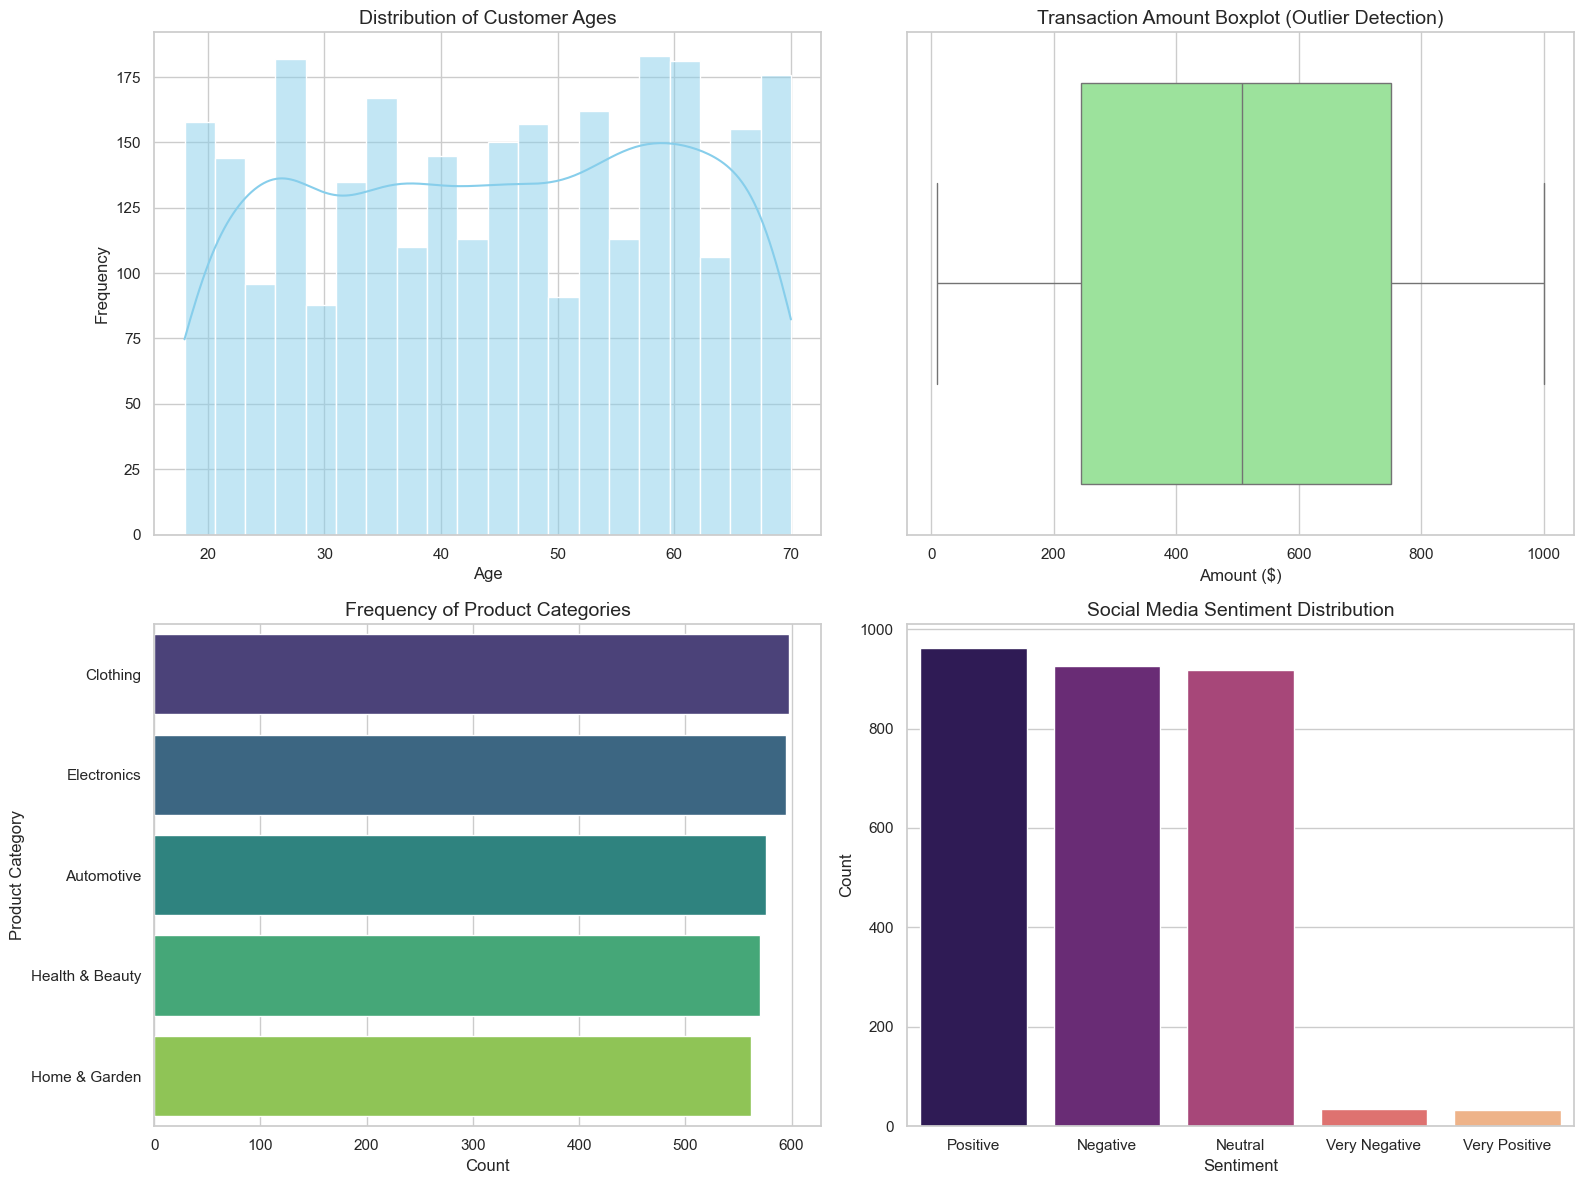

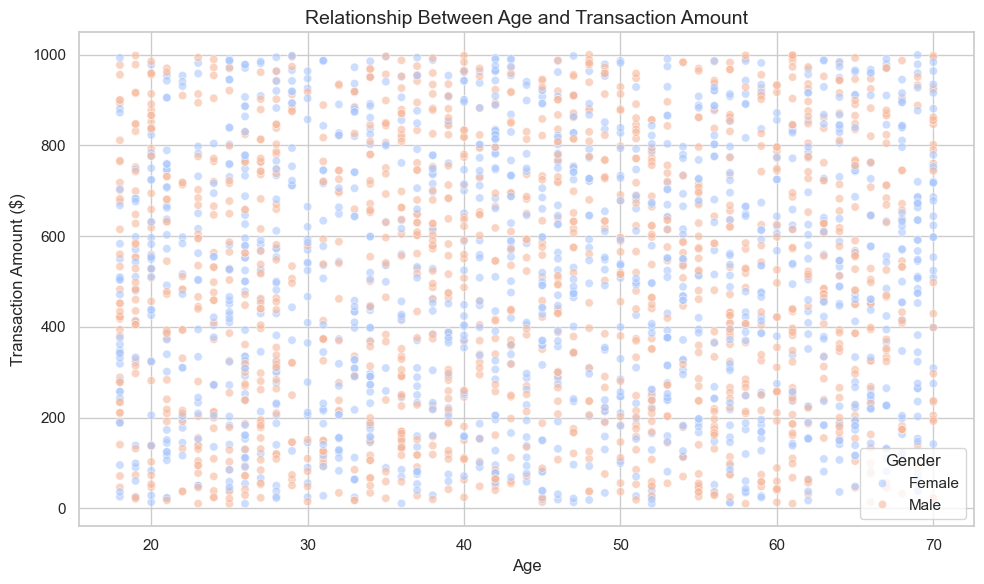

In [7]:
# Initialize a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Frequency Distribution: Age (Histogram with KDE)
sns.histplot(demo_df_clean['Age_Num'], bins=20, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Customer Ages', fontsize=14)
axes[0, 0].set_xlabel('Age', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)

# 2. Outlier Detection: Transaction Amounts (Boxplot)
sns.boxplot(x=trans_df_clean['Amount_Num'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Transaction Amount Boxplot (Outlier Detection)', fontsize=14)
axes[0, 1].set_xlabel('Amount ($)', fontsize=12)

# 3. Dominant Categories: Product Categories (Countplot)
sns.countplot(data=trans_df, y='ProductCategory', order=trans_df['ProductCategory'].value_counts().index, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Frequency of Product Categories', fontsize=14)
axes[1, 0].set_xlabel('Count', fontsize=12)
axes[1, 0].set_ylabel('Product Category', fontsize=12)

# 4. Imbalanced Categories: Social Media Sentiment (Countplot)
sns.countplot(data=social_df, x='Sentiment', order=social_df['Sentiment'].value_counts().index, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Social Media Sentiment Distribution', fontsize=14)
axes[1, 1].set_xlabel('Sentiment', fontsize=12)
axes[1, 1].set_ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

# 5. Variable Relationships: Scatter plot of Age vs Amount (Requires Merging)
merged_df = pd.merge(demo_df_clean, trans_df_clean, on='CustomerID', how='inner')

if not merged_df.empty:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=merged_df, x='Age_Num', y='Amount_Num', hue='Gender', alpha=0.6, palette='coolwarm')
    plt.title('Relationship Between Age and Transaction Amount', fontsize=14)
    plt.xlabel('Age', fontsize=12)
    plt.ylabel('Transaction Amount ($)', fontsize=12)
    plt.legend(title='Gender')
    plt.tight_layout()
    plt.show()

## Step 7: Interpretation of Visualizations and Numerical Outputs

**1. Patterns and Trends Observed (Numerical Distributions)**
The age distribution (Histogram) displays a relatively flat, uniform spread between 18 and 70 years rather than a normalized bell curve. The mean age (~44.6) and median age (45.0) are nearly identical, confirming that after the biological impossibilities (e.g., 150 years) were removed, the age dataset is highly symmetrical. 

**2. Relationships Between Variables**
The scatter plot merging Age and Transaction Amount shows a highly dispersed "cloud" of data points. There is no distinct linear correlation or trend line suggesting that older or younger customers spend significantly more or less. Furthermore, segmenting by Gender did not reveal any distinct clustering in spending habits based on age.

**3. Dominant and Imbalanced Categories**
*   **Imbalance:** The social media sentiment chart reveals a severe class imbalance. Positive and Negative sentiments dominate, while "Very Negative" and "Very Positive" occurrences are functionally non-existent.
*   **Dominance:** The product category count plot shows a relatively balanced spread across most items, with `Clothing` and `Electronics` holding a slight dominant edge.

**4. Potential Anomalies or Outliers**
The Transaction Amount boxplot effectively highlights several high-value outliers (transactions nearing $1,000) that fall far outside the interquartile range (IQR). Prior to numerical cleaning, extreme negative values (-$100) and text entries ("Free") were present, representing severe data entry anomalies.

**5. Observations Relevant to Future Machine Learning**
*   **Scaling Requirements:** The high variance ($83,676.88) and standard deviation ($289.27) in the `Amount` feature dictates that standard scaling or min-max normalization must be applied. Otherwise, gradient-descent and distance-based algorithms (like KNN) will be heavily skewed by the dollar values.
*   **Imbalance Handling:** The sentiment class imbalance means classification models will become heavily biased. Techniques like SMOTE (Synthetic Minority Over-sampling Technique) or class weighting will be necessary to prevent poor predictive accuracy for minority sentiment classes.